# A/B тест новой формы оплаты


## 0. Библиотеки

In [ ]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)

# одинаковые цвета для групп на всех графиках
COL = {'A': '#8a94a6', 'B': '#2f6fed'}

plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

rng = np.random.default_rng(42)   # чтобы бутстреп повторялся один в один

## 1. Загрузка

Строка в листе платежей это попытка, а не человек. Один пользователь может пытаться оплатить несколько раз, это важно для шага 6.
Пустое значение в step2, step3 или step4 значит, что человек до этого шага не дошёл.

In [ ]:
PATH = '/content/dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f (1).xlsx'

users = pd.read_excel(PATH, sheet_name='Пользователи')
pay = pd.read_excel(PATH, sheet_name='Платежи')

print('пользователи:', users.shape)
print('платежи:', pay.shape)
users.head()

пользователи: (1504, 5)
платежи: (2661, 7)


,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


In [ ]:
pay.head()

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


## 2. EDA

Ищем, что в данных не так, до того как считать метрики.

In [ ]:
# пропуски
print(users.isna().sum())
print()
print(pay.isna().sum())

user_id        0
group          1
age            0
city           1
device_type    0
dtype: int64

payment_id            0
user_id               1
group                 0
step1_opened          0
step2_entered       405
step3_confirmed     942
step4_success      1139
dtype: int64


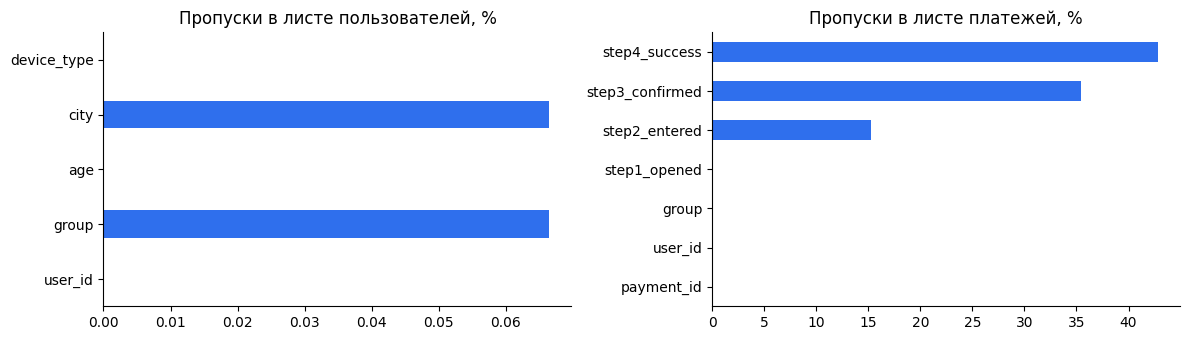

In [ ]:

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))

users.isna().mean().mul(100).plot.barh(ax=ax[0], color='#2f6fed')
ax[0].set_title('Пропуски в листе пользователей, %')

pay.isna().mean().mul(100).plot.barh(ax=ax[1], color='#2f6fed')
ax[1].set_title('Пропуски в листе платежей, %')

plt.tight_layout()
plt.show()

В пользователях по одному пропуску в group и city, в платежах один пропуск в user_id. Пропуски в step2, step3, step4 нормальные: так выглядят люди, которые отвалились по дороге.

In [ ]:
# группы, устройства, города
print(users['group'].value_counts(dropna=False), '\n')
print(users['device_type'].value_counts(dropna=False), '\n')
print(users['city'].value_counts(dropna=False))

group
A      752
B      751
NaN      1
Name: count, dtype: int64 

device_type
android    777
ios        727
Name: count, dtype: int64 

city
Москва    595
Регион    514
СПб       394
NaN         1
Name: count, dtype: int64


count    1504.000000
mean       32.745346
std         8.410915
min        -5.000000
25%        27.000000
50%        33.000000
75%        38.000000
max       150.000000
Name: age, dtype: float64


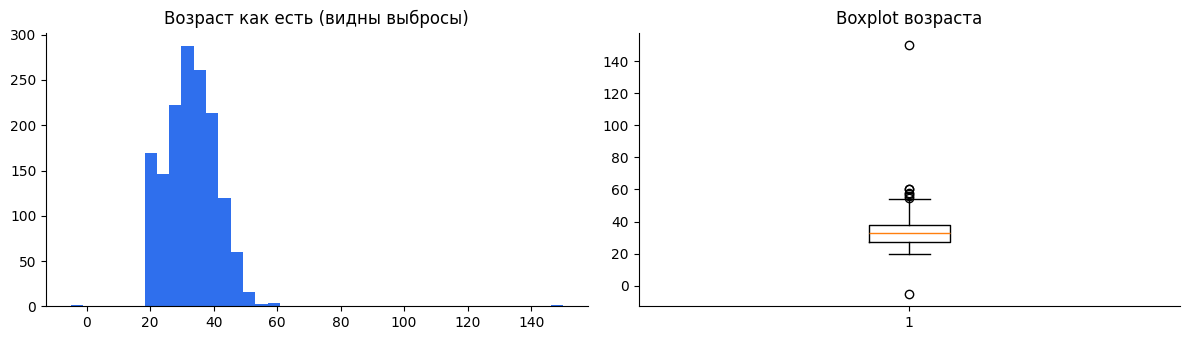

,user_id,group,age,city,device_type
1501,9002,A,-5,СПб,android
1502,9003,B,150,Регион,ios


In [ ]:
# возраст: посмотрим на распределение и на подозрительные значения
print(users['age'].describe())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(users['age'], bins=40, color='#2f6fed')
ax[0].set_title('Возраст как есть (видны выбросы)')

ax[1].boxplot(users['age'])
ax[1].set_title('Boxplot возраста')
plt.tight_layout()
plt.show()

users[(users['age'] < 14) | (users['age'] > 90)]

In [ ]:
# дубли
print('дубли user_id в users:', users['user_id'].duplicated().sum())
print('дубли payment_id в платежах:', pay['payment_id'].duplicated().sum())
print('повторы user_id в платежах:', pay['user_id'].duplicated().sum())   # это нормально, несколько попыток на человека

дубли user_id в users: 0
дубли payment_id в платежах: 0
повторы user_id в платежах: 1159


In [ ]:
# логика воронки: следующий шаг не может быть раньше предыдущего
steps = ['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']

for prev, nxt in zip(steps, steps[1:]):
    minutes = (pay[nxt] - pay[prev]).dt.total_seconds() / 60
    print(prev, '->', nxt, '| отрицательных:', (minutes < 0).sum(), '| от', minutes.min(), 'до', minutes.max(), 'мин')

print()
print('период теста:', pay['step1_opened'].min(), '-', pay['step1_opened'].max())

step1_opened -> step2_entered | отрицательных: 0 | от 1.0 до 13.0 мин
step2_entered -> step3_confirmed | отрицательных: 0 | от 1.0 до 11.0 мин
step3_confirmed -> step4_success | отрицательных: 0 | от 1.0 до 9.0 мин

период теста: 2024-04-01 00:19:00 - 2024-04-30 23:17:00


In [ ]:
# платежи с проблемами в user_id или группе
print('без user_id:')
print(pay[pay['user_id'].isna()])

print()
print('user_id, которых нет в users:', (~pay['user_id'].isin(users['user_id']) & pay['user_id'].notna()).sum())

chk = pay.merge(users[['user_id', 'group']], on='user_id', how='left', suffixes=('_pay', '_user'))
print()
print('группа в платеже не совпадает с группой пользователя:')
print(chk[chk['group_pay'] != chk['group_user']])

без user_id:
      payment_id  user_id group        step1_opened step2_entered step3_confirmed step4_success
2660       99003      NaN     A 2024-04-12 09:15:00           NaT             NaT           NaT

user_id, которых нет в users: 0

группа в платеже не совпадает с группой пользователя:
      payment_id  user_id group_pay        step1_opened       step2_entered     step3_confirmed       step4_success group_user
2659       99002   1010.0         B 2024-04-08 14:20:00 2024-04-08 14:23:00 2024-04-08 14:28:00 2024-04-08 14:29:00          A
2660       99003      NaN         A 2024-04-12 09:15:00                 NaT                 NaT                 NaT        NaN


Найдено 6 проблемных записей:

- пользователь 9001: нет группы
- пользователи 9002 и 9003: возраст -5 и 150
- пользователь 9004: нет города
- платёж 99003: нет user_id
- платёж 99002: пользователь 1010 в группе A, а в платеже стоит B

## 3. Чистка

Что делаю с каждой проблемой:

- нет группы (9001): удаляю, непонятно куда его отнести
- странный возраст (9002, 9003): возраст ставлю в NaN, пользователей оставляю, на ключевую метрику возраст не влияет
- нет города (9004): оставляю, город нужен только для сегментов
- платёж без user_id: удаляю, непонятно чей он
- конфликт групп: удаляю платёж, сплит был по клиентам, группу всегда беру из таблицы пользователей

In [ ]:
# пользователи
users_clean = users[users['group'].notna()].copy()

bad_age = (users_clean['age'] < 14) | (users_clean['age'] > 90)
users_clean.loc[bad_age, 'age'] = np.nan

print('пользователей было', len(users), 'стало', len(users_clean))

пользователей было 1504 стало 1503


In [ ]:
# платежи
pay_clean = pay.dropna(subset=['user_id']).copy()
pay_clean['user_id'] = pay_clean['user_id'].astype(int)

# подтягиваем группу, устройство и город из таблицы пользователей
pay_clean = pay_clean.rename(columns={'group': 'group_in_pay'})
pay_clean = pay_clean.merge(users_clean[['user_id', 'group', 'device_type', 'city']],
                            on='user_id', how='inner')

# убираем платежи, где группа не совпала
conflict = pay_clean['group_in_pay'] != pay_clean['group']
print('конфликтных платежей:', conflict.sum())
pay_clean = pay_clean[~conflict].drop(columns='group_in_pay')

print('платежей было', len(pay), 'стало', len(pay_clean))

конфликтных платежей: 1
платежей было 2661 стало 2659


## 4. Состав выборки

Смотрим, как устроены группы и как шли попытки во времени.

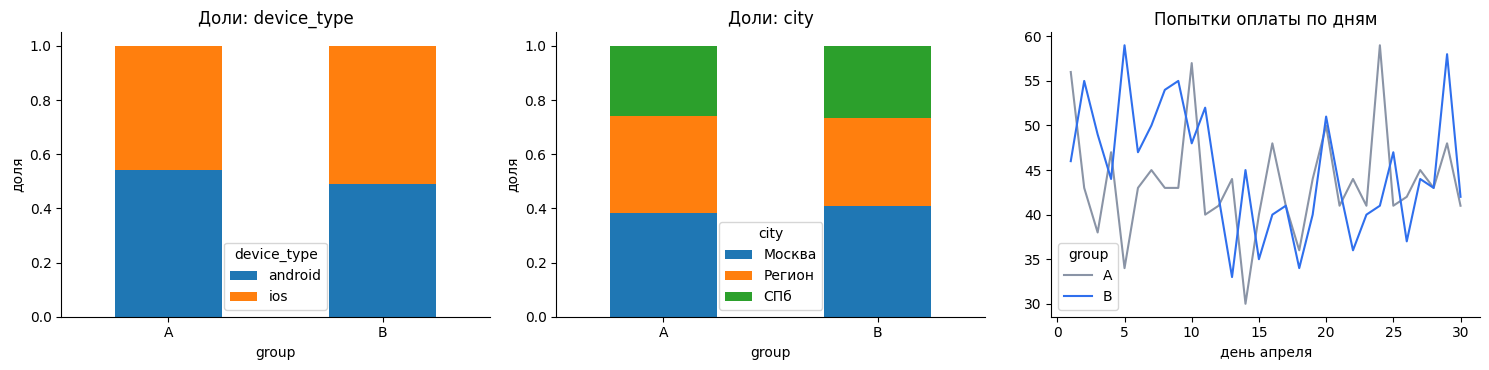

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))

# устройства и города по группам, в долях
for i, col in enumerate(['device_type', 'city']):
    share = pd.crosstab(users_clean['group'], users_clean[col], normalize='index')
    share.plot.bar(stacked=True, ax=ax[i], rot=0)
    ax[i].set_title('Доли: ' + col)
    ax[i].set_ylabel('доля')

# число попыток по дням
daily = pay_clean.assign(day=pay_clean['step1_opened'].dt.day).groupby(['day', 'group']).size().unstack()
daily.plot(ax=ax[2], color=[COL['A'], COL['B']])
ax[2].set_title('Попытки оплаты по дням')
ax[2].set_xlabel('день апреля')

plt.tight_layout()
plt.show()

1    741
2    442
3    238
4     80
Name: count, dtype: int64


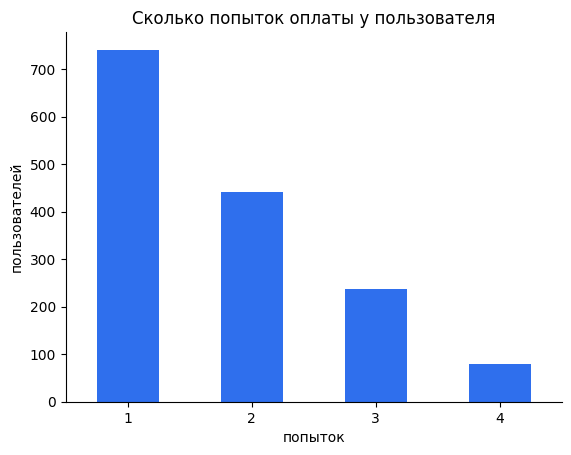

In [ ]:
# сколько попыток на пользователя
tries = pay_clean.groupby('user_id').size()
print(tries.value_counts().sort_index())

tries.value_counts().sort_index().plot.bar(color='#2f6fed', rot=0)
plt.title('Сколько попыток оплаты у пользователя')
plt.xlabel('попыток')
plt.ylabel('пользователей')
plt.show()

У большинства пользователей одна попытка, но заметная часть пробовала 2 и больше раз. Поэтому в шаге 7 считаю тест на уровне пользователя.

## 5. Воронка

Превращаю даты в флаги (дошёл до шага или нет) и считаю по группам.

In [ ]:
pay_clean['reached_2'] = pay_clean['step2_entered'].notna().astype(int)
pay_clean['reached_3'] = pay_clean['step3_confirmed'].notna().astype(int)
pay_clean['success'] = pay_clean['step4_success'].notna().astype(int)

funnel = pay_clean.groupby('group').agg(
    opened=('payment_id', 'count'),
    entered=('reached_2', 'sum'),
    confirmed=('reached_3', 'sum'),
    success=('success', 'sum'))
funnel['conv_1_4'] = funnel['success'] / funnel['opened']
funnel

,opened,entered,confirmed,success,conv_1_4
group,,,,,
A,1308,1061,758,651,0.497706
B,1351,1194,960,870,0.643967


In [ ]:
# конверсия между соседними шагами
step_conv = pd.DataFrame({
    '1->2': funnel['entered'] / funnel['opened'],
    '2->3': funnel['confirmed'] / funnel['entered'],
    '3->4': funnel['success'] / funnel['confirmed'],
    '1->4': funnel['conv_1_4']})
step_conv.round(4)

,1->2,2->3,3->4,1->4
group,,,,
A,0.8112,0.7144,0.8588,0.4977
B,0.8838,0.8040,0.9062,0.6440


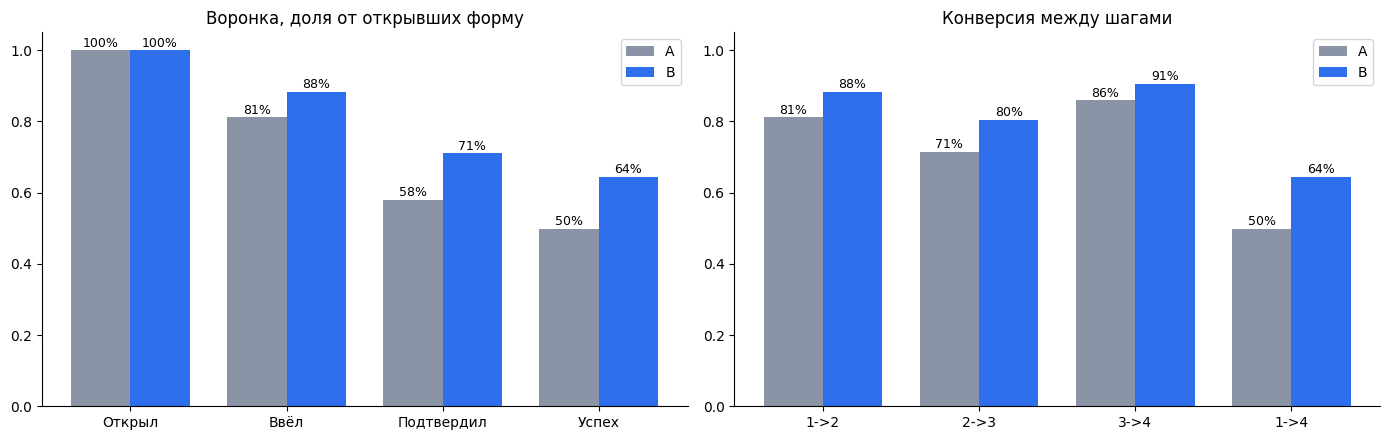

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

# воронка в долях от открывших форму
share = funnel[['opened', 'entered', 'confirmed', 'success']].div(funnel['opened'], axis=0)
labels = ['Открыл', 'Ввёл', 'Подтвердил', 'Успех']
x = np.arange(4)
for i, g in enumerate(['A', 'B']):
    bars = ax[0].bar(x + (i - 0.5) * 0.38, share.loc[g], 0.38, color=COL[g], label=g)
    for xi, v in zip(x + (i - 0.5) * 0.38, share.loc[g]):
        ax[0].text(xi, v + 0.01, f'{v:.0%}', ha='center', fontsize=9)
ax[0].set_xticks(x)
ax[0].set_xticklabels(labels)
ax[0].set_title('Воронка, доля от открывших форму')
ax[0].legend()

# конверсия между шагами
x = np.arange(4)
for i, g in enumerate(['A', 'B']):
    ax[1].bar(x + (i - 0.5) * 0.38, step_conv.loc[g], 0.38, color=COL[g], label=g)
    for xi, v in zip(x + (i - 0.5) * 0.38, step_conv.loc[g]):
        ax[1].text(xi, v + 0.01, f'{v:.0%}', ha='center', fontsize=9)
ax[1].set_xticks(x)
ax[1].set_xticklabels(step_conv.columns)
ax[1].set_ylim(0, 1.05)
ax[1].set_title('Конверсия между шагами')
ax[1].legend()

plt.tight_layout()
plt.show()

Конверсия 1->4: в A около 49.8%, в B около 64.4%, разница примерно 14.6 п.п.
Группа B лучше на каждом переходе. Меня здесь смущает 2->3 и 3->4: упрощённое заполнение реквизитов должно помогать на шаге 1->2, а там, где человек уже ввёл данные, большой разницы я бы не ждала. К этому вернёмся в выводах.

Пока это только описательные цифры, разница могла получиться случайно.

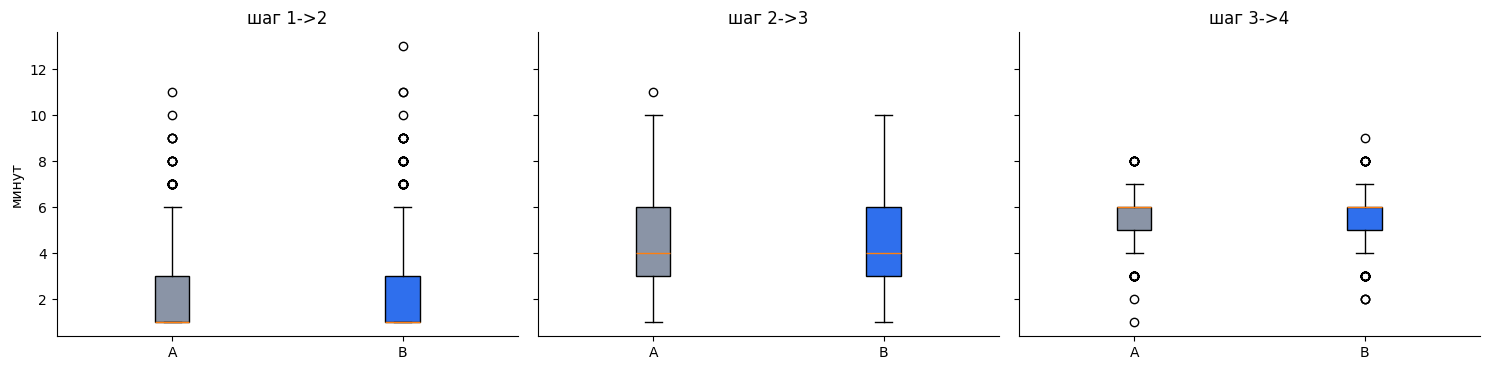

       шаг 1->2  шаг 2->3  шаг 3->4
group                              
A           1.0       4.0       6.0
B           1.0       4.0       6.0


In [ ]:
# сколько минут занимает каждый шаг, вдруг форма B реально быстрее
durations = pd.DataFrame({
    'шаг 1->2': (pay_clean['step2_entered'] - pay_clean['step1_opened']).dt.total_seconds() / 60,
    'шаг 2->3': (pay_clean['step3_confirmed'] - pay_clean['step2_entered']).dt.total_seconds() / 60,
    'шаг 3->4': (pay_clean['step4_success'] - pay_clean['step3_confirmed']).dt.total_seconds() / 60,
    'group': pay_clean['group']})

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for i, col in enumerate(['шаг 1->2', 'шаг 2->3', 'шаг 3->4']):
    data = [durations.loc[durations['group'] == g, col].dropna() for g in ['A', 'B']]
    bp = ax[i].boxplot(data, patch_artist=True)
    ax[i].set_xticklabels(['A', 'B'])
    for patch, g in zip(bp['boxes'], ['A', 'B']):
        patch.set_facecolor(COL[g])
    ax[i].set_title(col)
ax[0].set_ylabel('минут')
plt.tight_layout()
plt.show()

print(durations.groupby('group')[['шаг 1->2', 'шаг 2->3', 'шаг 3->4']].median())

Время на шагах в обеих группах почти одинаковое, медианы совпадают. То есть форма B не стала быстрее, а конверсия при этом выше. Это ещё один повод спросить у команды, что именно менялось в варианте B.

## 6. Проверка сплита

Прежде чем верить разнице, проверяю, что группы сравнимы. Использую хи-квадрат: большой p-value значит, что различий между группами не видно, а нам именно это и нужно.

In [ ]:
# SRM: группы должны быть примерно равны по размеру
counts = users_clean['group'].value_counts()
print(counts)
print('p-value SRM:', stats.chisquare(counts).pvalue)

# баланс по устройству и городу
for col in ['device_type', 'city']:
    table = pd.crosstab(users_clean['group'], users_clean[col])
    print(col, 'p-value:', round(stats.chi2_contingency(table)[1], 3))

# баланс по возрасту
age_a = users_clean.loc[users_clean['group'] == 'A', 'age'].dropna()
age_b = users_clean.loc[users_clean['group'] == 'B', 'age'].dropna()
print('возраст, средний A:', round(age_a.mean(), 2), 'B:', round(age_b.mean(), 2),
      'p-value:', round(stats.ttest_ind(age_a, age_b, equal_var=False).pvalue, 3))

group
A    752
B    751
Name: count, dtype: int64
p-value SRM: 0.979421561620276
device_type p-value: 0.053
city p-value: 0.466
возраст, средний A: 32.74 B: 32.65 p-value: 0.831


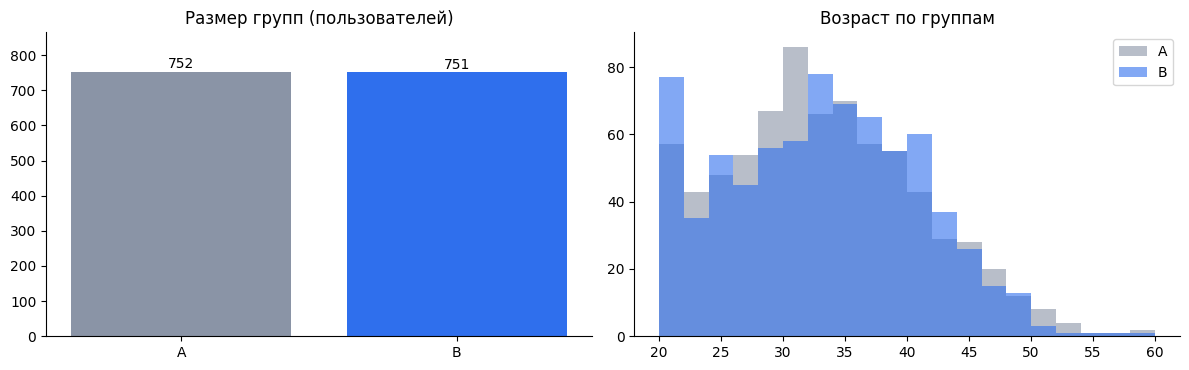

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))

ax[0].bar(counts.index, counts.values, color=[COL[g] for g in counts.index])
ax[0].set_title('Размер групп (пользователей)')
ax[0].set_ylim(0, counts.max() * 1.15)
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 10, v, ha='center')

ax[1].hist(age_a, bins=20, alpha=0.6, color=COL['A'], label='A')
ax[1].hist(age_b, bins=20, alpha=0.6, color=COL['B'], label='B')
ax[1].set_title('Возраст по группам')
ax[1].legend()

plt.tight_layout()
plt.show()

Группы 752 и 751, SRM p около 0.98, всё в порядке. По городу и возрасту различий нет.
По устройству p около 0.053: в A немного больше Android. Это на грани, поэтому в шаге 9 проверю, что эффект одинаковый на Android и iOS. Если так, перекос на вывод не влияет.

## 7. Тест на уровне пользователя

Сплит делался по пользователям, а в платежах у человека бывает несколько попыток. Попытки одного человека связаны между собой, а обычный z-тест для долей требует независимых наблюдений. Если прогнать его по строкам платежей, ошибка получится слишком маленькой, а p-value слишком уверенным.

Поэтому сворачиваю таблицу до одной строки на пользователя и сравниваю уже там.

In [ ]:
per_user = pay_clean.groupby(['user_id', 'group']).agg(
    attempts=('payment_id', 'count'),
    successes=('success', 'sum')).reset_index()

# была ли у пользователя хотя бы одна успешная оплата
per_user['has_success'] = (per_user['successes'] > 0).astype(int)

per_user.groupby('group')[['attempts', 'successes', 'has_success']].mean()

,attempts,successes,has_success
group,,,
A,1.741678,0.866844,0.656458
B,1.801333,1.160000,0.804000


Попыток на пользователя примерно столько же (1.74 в A и 1.80 в B), то есть новая форма не заставила людей пробовать чаще. А вот доля пользователей с успешной оплатой отличается: около 65.6% в A против 80.4% в B.

In [ ]:
# z-тест для двух долей
# H0: доля пользователей с успешной оплатой в A и B одинаковая
a = per_user[per_user['group'] == 'A']
b = per_user[per_user['group'] == 'B']

x_a, n_a = a['has_success'].sum(), len(a)
x_b, n_b = b['has_success'].sum(), len(b)
p_a, p_b = x_a / n_a, x_b / n_b

p_pool = (x_a + x_b) / (n_a + n_b)
se = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
z = (p_b - p_a) / se
p_value = 2 * (1 - stats.norm.cdf(abs(z)))

print('A:', round(p_a, 4), ' B:', round(p_b, 4))
print('разница:', round((p_b - p_a) * 100, 2), 'п.п.')
print('z =', round(z, 2), ' p-value =', p_value)

A: 0.6565  B: 0.804
разница: 14.75 п.п.
z = 6.44  p-value = 1.2020162643011645e-10


In [ ]:
# число успешных оплат на пользователя
# и распределение не нормальное, поэтому беру Манна-Уитни
res = stats.mannwhitneyu(b['successes'], a['successes'])
print('среднее успешных оплат, A:', round(a['successes'].mean(), 3), ' B:', round(b['successes'].mean(), 3))
print('p-value:', res.pvalue)

среднее успешных оплат, A: 0.867  B: 1.16
p-value: 6.280059019727773e-12


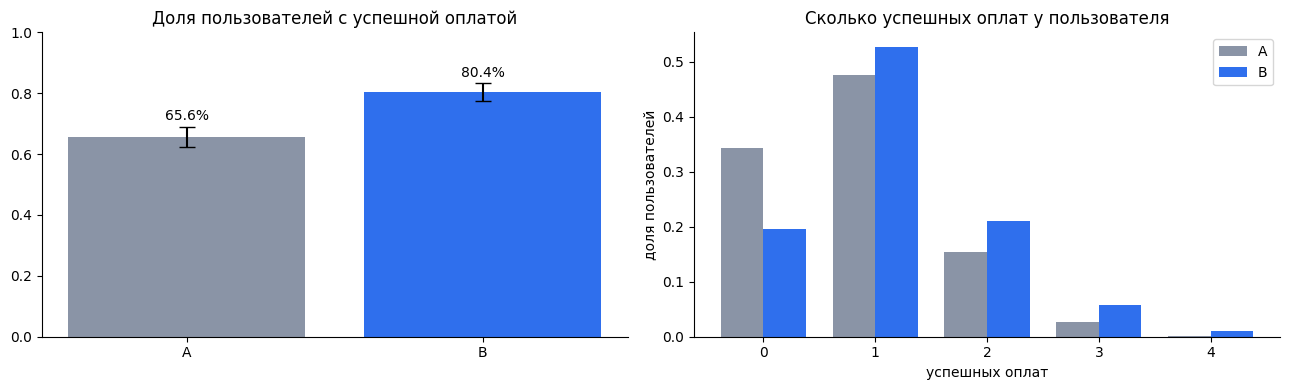

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

# доля пользователей с успешной оплатой (с 95% интервалом по формуле для долей)
for i, (g, p_, n_) in enumerate([('A', p_a, n_a), ('B', p_b, n_b)]):
    err = 1.96 * np.sqrt(p_ * (1 - p_) / n_)
    ax[0].bar(i, p_, color=COL[g], yerr=err, capsize=6)
    ax[0].text(i, p_ + err + 0.02, f'{p_:.1%}', ha='center')
ax[0].set_xticks([0, 1])
ax[0].set_xticklabels(['A', 'B'])
ax[0].set_ylim(0, 1)
ax[0].set_title('Доля пользователей с успешной оплатой')

# распределение числа успешных оплат
vals = range(0, int(per_user['successes'].max()) + 1)
ca = a['successes'].value_counts(normalize=True).reindex(vals, fill_value=0)
cb = b['successes'].value_counts(normalize=True).reindex(vals, fill_value=0)
w = 0.38
ax[1].bar(np.array(vals) - w / 2, ca, w, color=COL['A'], label='A')
ax[1].bar(np.array(vals) + w / 2, cb, w, color=COL['B'], label='B')
ax[1].set_title('Сколько успешных оплат у пользователя')
ax[1].set_xlabel('успешных оплат')
ax[1].set_ylabel('доля пользователей')
ax[1].legend()

plt.tight_layout()
plt.show()

p-value около 1e-10, случайность практически исключена. На графике справа видно, что в A заметно больше пользователей с нулём успешных оплат, а в B больше тех, у кого одна и две.

## 8. Бутстреп для конверсии 1->4

Ключевая метрика считается по попыткам: успешные делить на все попытки. Нужен доверительный интервал, который учитывает, что попытки сидят внутри пользователей.

Идея: много раз беру случайную выборку пользователей с возвращением (вместе со всеми их попытками), каждый раз считаю разницу B минус A. Разброс этих разниц и есть неопределённость оценки.

In [ ]:
def boot_diff(a_df, b_df, n_iter=5000):
    # разница конверсий по попыткам (B минус A) на бутстреп-выборках пользователей
    sa, ta = a_df['successes'].values, a_df['attempts'].values
    sb, tb = b_df['successes'].values, b_df['attempts'].values
    out = np.empty(n_iter)
    for i in range(n_iter):
        ia = rng.integers(0, len(sa), len(sa))   # индексы случайных пользователей A
        ib = rng.integers(0, len(sb), len(sb))
        out[i] = sb[ib].sum() / tb[ib].sum() - sa[ia].sum() / ta[ia].sum()
    return out

observed = b['successes'].sum() / b['attempts'].sum() - a['successes'].sum() / a['attempts'].sum()
diffs = boot_diff(a, b)
low, high = np.percentile(diffs, [2.5, 97.5])

print('разница в данных:', round(observed * 100, 2), 'п.п.')
print('95% интервал: от', round(low * 100, 2), 'до', round(high * 100, 2), 'п.п.')
print('доля бутстреп-разниц <= 0:', (diffs <= 0).mean())

разница в данных: 14.63 п.п.
95% интервал: от 10.96 до 18.25 п.п.
доля бутстреп-разниц <= 0: 0.0


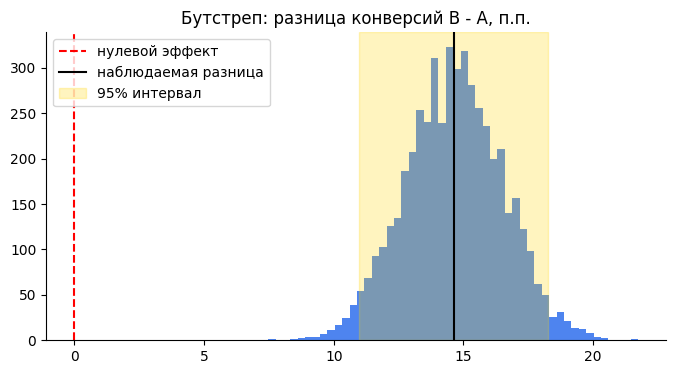

In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(diffs * 100, bins=50, color='#2f6fed', alpha=0.85)
plt.axvline(0, color='red', ls='--', label='нулевой эффект')
plt.axvline(observed * 100, color='black', label='наблюдаемая разница')
plt.axvspan(low * 100, high * 100, color='gold', alpha=0.25, label='95% интервал')
plt.title('Бутстреп: разница конверсий B - A, п.п.')
plt.legend()
plt.show()

Прирост примерно от 11 до 18 п.п. Ноль в интервал не попадает. Даже нижняя граница это большой эффект.

## 9. Сегменты

Хочу понять, не тащит ли весь результат один сегмент. Заодно это проверка перекоса по устройству из шага 6.
Для каждого сегмента считаю разницу конверсий и интервал тем же бутстрепом по пользователям.

In [ ]:
# добавляю устройство и город к таблице на уровне пользователя
per_user = per_user.merge(users_clean[['user_id', 'device_type', 'city']], on='user_id')

rows = []
for col in ['device_type', 'city']:
    for val in per_user[col].dropna().unique():
        sub = per_user[per_user[col] == val]
        sa_, sb_ = sub[sub['group'] == 'A'], sub[sub['group'] == 'B']
        conv_a = sa_['successes'].sum() / sa_['attempts'].sum()
        conv_b = sb_['successes'].sum() / sb_['attempts'].sum()
        d = boot_diff(sa_, sb_, n_iter=2000)
        lo, hi = np.percentile(d, [2.5, 97.5])
        rows.append([col, val, conv_a, conv_b, (conv_b - conv_a) * 100, lo * 100, hi * 100, len(sub)])

seg = pd.DataFrame(rows, columns=['признак', 'сегмент', 'конв_A', 'конв_B', 'разница_пп', 'ниж', 'верх', 'пользователей'])
seg.round(3)

,признак,сегмент,конв_A,конв_B,разница_пп,ниж,верх,пользователей
0,device_type,ios,0.508,0.650,14.122,8.870,19.626,725
1,device_type,android,0.489,0.638,14.934,10.000,20.010,776
2,city,Москва,0.468,0.651,18.267,12.023,24.156,594
3,city,Регион,0.508,0.614,10.689,3.769,17.434,513
4,city,СПб,0.526,0.669,14.238,7.295,21.412,393


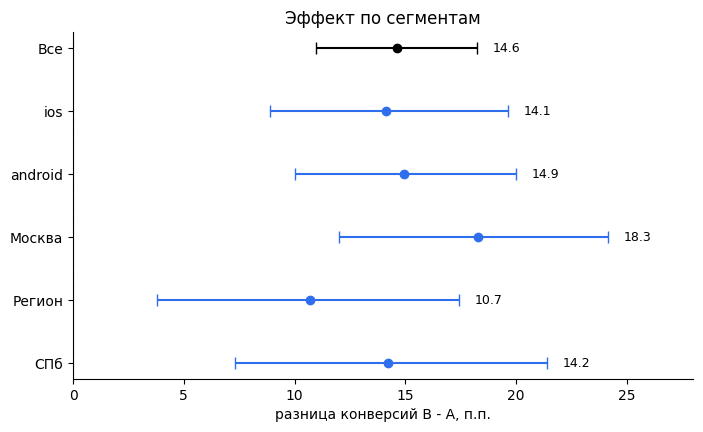

In [ ]:
# forest plot: разница и интервал по сегментам
total = [observed * 100, low * 100, high * 100]
names = ['Все'] + list(seg['сегмент'])
diff = [total[0]] + list(seg['разница_пп'])
lo_ = [total[1]] + list(seg['ниж'])
hi_ = [total[2]] + list(seg['верх'])

plt.figure(figsize=(8, 4.5))
for i, (n, d, l, h) in enumerate(zip(names[::-1], diff[::-1], lo_[::-1], hi_[::-1])):
    plt.errorbar(d, i, xerr=[[d - l], [h - d]], fmt='o', capsize=4,
                 color='black' if n == 'Все' else '#2f6fed')
    plt.text(h + 0.7, i, f'{d:.1f}', va='center', fontsize=9)
plt.yticks(range(len(names)), names[::-1])
plt.axvline(0, color='red', ls='--')
plt.xlim(0, 28)
plt.xlabel('разница конверсий B - A, п.п.')
plt.title('Эффект по сегментам')
plt.show()

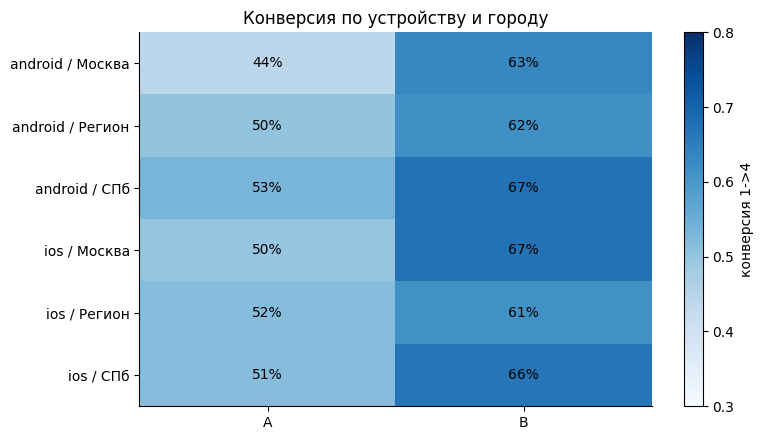

In [ ]:
# конверсия по сочетанию устройство x город для каждой группы
pay_clean['seg'] = pay_clean['device_type'] + ' / ' + pay_clean['city']
heat = pay_clean.pivot_table(index='seg', columns='group', values='success', aggfunc='mean')
heat['разница'] = (heat['B'] - heat['A']) * 100

plt.figure(figsize=(8, 4.5))
plt.imshow(heat[['A', 'B']], cmap='Blues', aspect='auto', vmin=0.3, vmax=0.8)
plt.xticks([0, 1], ['A', 'B'])
plt.yticks(range(len(heat)), heat.index)
for i in range(len(heat)):
    for j, g in enumerate(['A', 'B']):
        plt.text(j, i, f'{heat[g].iloc[i]:.0%}', ha='center', va='center')
plt.colorbar(label='конверсия 1->4')
plt.title('Конверсия по устройству и городу')
plt.tight_layout()
plt.show()

В каждом сегменте B лучше A. На Android и iOS разница почти одинаковая, так что перекос по устройству картину не портит. В регионах прирост поменьше, но интервалы сегментов сильно пересекаются, делать из этого вывод вроде "в регионах форма хуже работает" я бы не стала.

Сегментов много, а чем больше сравнений, тем выше шанс найти что-то случайно. Поэтому использую их только как проверку устойчивости, а не чтобы искать лучший сегмент.

## 10. Динамика по неделям

Новая форма могла понравиться просто потому, что она новая, а потом эффект затух бы. Проверяю, держится ли разница до конца теста.

In [ ]:
pay_clean['week'] = ((pay_clean['step1_opened'].dt.day - 1) // 7 + 1).clip(upper=4)   # дни 29-30 идут в 4 неделю

weekly = pay_clean.pivot_table(index='week', columns='group', values='success', aggfunc='mean')
weekly['разница_пп'] = (weekly['B'] - weekly['A']) * 100
weekly['попыток'] = pay_clean.groupby('week').size()
weekly.round(3)

group,A,B,разница_пп,попыток
week,,,,
1,0.510,0.663,15.305,656
2,0.523,0.660,13.608,627
3,0.480,0.623,14.324,584
4,0.483,0.629,14.619,792


Разница держится на уровне +14-15 п.п. все четыре недели и к концу не уменьшается. Эффекта новизны я не вижу.

## 11. Итоговый график

Основные результаты

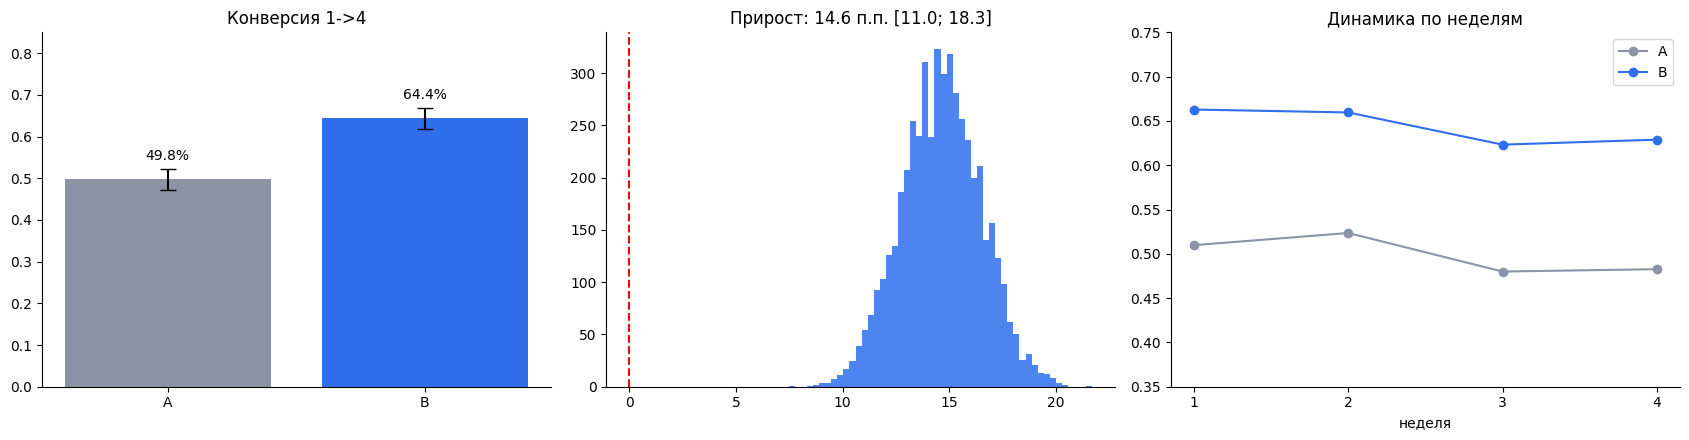

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# 1) конверсия 1->4 с интервалами из бутстрепа (интервал для каждой группы отдельно)
conv_a = a['successes'].sum() / a['attempts'].sum()
conv_b = b['successes'].sum() / b['attempts'].sum()
def boot_conv(df, n_iter=3000):
    s, t = df['successes'].values, df['attempts'].values
    res = np.empty(n_iter)
    for i in range(n_iter):
        idx = rng.integers(0, len(s), len(s))
        res[i] = s[idx].sum() / t[idx].sum()
    return np.percentile(res, [2.5, 97.5])

for i, (g, c, df) in enumerate([('A', conv_a, a), ('B', conv_b, b)]):
    lo, hi = boot_conv(df)
    ax[0].bar(i, c, color=COL[g], yerr=[[c - lo], [hi - c]], capsize=6)
    ax[0].text(i, hi + 0.02, f'{c:.1%}', ha='center')
ax[0].set_xticks([0, 1])
ax[0].set_xticklabels(['A', 'B'])
ax[0].set_ylim(0, 0.85)
ax[0].set_title('Конверсия 1->4')

# 2) бутстреп разницы
ax[1].hist(diffs * 100, bins=50, color='#2f6fed', alpha=0.85)
ax[1].axvline(0, color='red', ls='--')
ax[1].set_title(f'Прирост: {observed * 100:.1f} п.п. [{low * 100:.1f}; {high * 100:.1f}]')

# 3) по неделям
for g in ['A', 'B']:
    ax[2].plot(weekly.index, weekly[g], marker='o', color=COL[g], label=g)
ax[2].set_xticks([1, 2, 3, 4])
ax[2].set_ylim(0.35, 0.75)
ax[2].set_xlabel('неделя')
ax[2].set_title('Динамика по неделям')
ax[2].legend()

plt.tight_layout()
plt.show()

## 12. Выводы

Данные. Нашла 6 проблемных записей и убрала или починила их. На результат это почти не повлияло.

Сплит. Группы по 752 и 751 пользователя, SRM в порядке, по городу и возрасту группы похожи, по устройству небольшой перекос, который на эффект не влияет.

Результат. Конверсия 1->4 выросла с 49.8% до 64.4%, это примерно +14.6 п.п. (около +29% относительно), 95% интервал от 11 до 18 п.п. На уровне пользователей доля с успешной оплатой выросла с 65.6% до 80.4%, p около 1e-10.

Устойчивость. Эффект положительный во всех сегментах и во все четыре недели.

Рекомендация. Раскатывать на всех пользователей, лучше постепенно (например 50%, потом 100%) и с мониторингом.

Что остаётся неясным:

1. Конверсия выросла и на шагах 2->3 и 3->4, хотя автозаполнение там напрямую ничего не меняет, и время на шагах не сократилось. Надо уточнить у команды, не менялось ли в B что-то ещё.
2. В данных нет гардрейл-метрик: ошибки оплаты, возвраты, неверно подставленные реквизиты, обращения в поддержку. Их стоит смотреть при раскатке.
3. Тест шёл один месяц, сезонность ЖКХ-платежей (например конец месяца) не проверена.